# Doublet detection

Two cells captured in one droplet share a barcode. In scATAC-seq such
doublets show up as spurious intermediate states and as clusters that bridge
real ones. Epione offers several detectors that see different things:

| Function | Idea | Needs |
|---|---|---|
| `epi.pp.doublets` → `epi.pp.bayes_doublets` (**default**) | generative model: a doublet's profile is a mixture of two singlet-type profiles; Bayes factor vs the best singlet type, doublet rate calibrated by EM | tile or peak matrix |
| `epi.pp.scrublet` | simulated doublets, kNN classifier (Scrublet / SnapATAC2) | tile or peak matrix |
| `epi.pp.archr_doublets` | ArchR's `addDoubletScores`: simulated doublets projected into iterative LSI + UMAP | tile matrix |
| `epi.pp.scdblfinder` | scDblFinder's scATAC mode: aggregated features, gradient-boosted classifier | tile or peak matrix |
| `epi.pp.amulet` | AMULET: too many loci covered by more than two fragments; also catches *homotypic* doublets | fragments |
| `epi.pp.combine_doublet_scores` | Fisher combination of AMULET and scDblFinder, which the scDblFinder authors found most robust | both |
| `epi.pp.filter_doublets` | removes cells: by default the `bayes_doublets` call; or ArchR's rule, a threshold, a class column | any of the above |

`scdblfinder`, `amulet` and `clamulet` wrap
[pyscdblfinder](https://github.com/omicverse/py-scDblFinder), the omicverse
port of R scDblFinder (`pip install 'epione[doublets]'`). `archr_doublets` is
a port of ArchR 1.0.3. Its agreement with ArchR is recorded in
`tests/parity/doublets/MANIFEST.md`, next to ArchR's agreement with itself
across seeds, which is low.

**Data with ground truth.** The ArchR paper (Granja et al. 2021, GEO
GSE162690) loaded a mixture of 11 genotyped cell lines into a 10x chip at a
high concentration on purpose, and called every barcode with demuxlet. A
doublet of two different lines is visible in the genotypes, so we can measure
each method. Demuxlet cannot see two cells of the *same* line, so a few
"singlets" are really homotypic doublets. We use the low-loading sample, with
about 21% genotype doublets among the cells with at least 1,000 fragments.

## Data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import epione as epi

d = epi.datasets.granja2021_cellline_mix("low", data_dir=os.environ.get("EPIONE_DOUBLETS_DIR"))
dmx = d["demuxlet"]
dmx["call"].value_counts()

call
AMB    36239
SNG    15268
DBL     3363
Name: count, dtype: int64

Demuxlet called every barcode, including empty droplets. We keep barcodes
with at least 1,000 unique fragments, ArchR's default `minFrags`, and build
the 500-bp tile matrix that ArchR and Scrublet use.

In [2]:
adata = epi.pp.import_fragments(d["fragments"], chrom_sizes=d["chrom_sizes"],
                                whitelist=list(dmx.index), min_num_fragments=1000)
epi.pp.add_tile_matrix(adata, bin_size=500)
adata.obs["demuxlet"] = dmx.loc[adata.obs_names, "call"].to_numpy()
adata.obs["cell_line"] = dmx.loc[adata.obs_names, "cell_line"].to_numpy()
print(adata)
adata.obs["demuxlet"].value_counts()

└─ scanning ~/.cache/epione/granja2021_cellline_mix/cellline_low.fragments.bgz.tsv.gz


  └─ imported 12,857 cells  (64,548,412 unique fragments)


└─ building tile matrix: 12,857 cells × 6,176,550 tiles (500 bp bins, strategy=paired-insertion)


  └─ tile matrix nnz=87,177,414
AnnData object with n_obs × n_vars = 12857 × 6176550
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'demuxlet', 'cell_line'
    uns: 'files', 'reference_sequences'


demuxlet
SNG    10155
DBL     2701
AMB        1
Name: count, dtype: int64

## Default: generative doublet model (`bayes_doublets`)

`epi.pp.doublets(adata)` runs `epi.pp.bayes_doublets`. It clusters the cells
into singlet types (LSI + Leiden on the 100k most frequently accessible
tiles) and asks, for every cell, whether its fragments are better explained by
one type profile or by a mixture `α·p_k + (1-α)·p_l` of two, integrating over
the unknown fraction α. The log posterior odds is the ranking score; the
doublet rate is started from Poisson loading statistics and calibrated by EM,
so `bayes_doublet_probability` is a calibrated posterior. Clusters that are
themselves populations of doublets are detected and not used as singlet types.
No doublets are simulated, so the result does not depend on a random seed
except through the clustering.

In [3]:
epi.pp.doublets(adata)                      # = epi.pp.bayes_doublets(adata)
print(adata.uns["bayes_doublet"])
adata.obs[["bayes_doublet_probability", "bayes_doublet_score", "bayes_doublet_class",
           "bayes_doublet_pair"]].head()

└─ [bayes_doublets] 12,857 cells, 100,000 features, rho0=0.111


  └─ [bayes_doublets] iter 0: rho=0.2371, kappa=1.000, K=12
  └─ [bayes_doublets] rho=0.111, kappa=1.000, called 1,424 doublets
{'rho': 0.1107382916909333, 'temper': 0.027307384809692647, 'calibration': 'loading', 'kappa': 1.0, 'n_types': 12, 'n_features': 100000, 'use_library': False, 'use_overlap': False, 'homotypic': False, 'n_iter': 0}


,bayes_doublet_probability,bayes_doublet_score,bayes_doublet_class,bayes_doublet_pair
barcode,,,,
AAACGAAAGTACCACT-1,0.094849,-2.255815,singlet,0+3
AAACGAAAGTGGTGTG-1,0.089918,-2.314636,singlet,4+1
AAACGAAAGTTCGACT-1,0.217653,-1.279395,singlet,0+3
AAACGAACAGCAACGA-1,0.092822,-2.279658,singlet,7+1
AAACGAACATAGACGG-1,0.097461,-2.225759,singlet,0+3


## Scrublet

In [4]:
sc = adata.copy()
epi.pp.select_features(sc)
epi.pp.scrublet(sc)
adata.obs["scrublet_score"] = sc.obs["doublet_score"].to_numpy()
adata.obs["scrublet_is_doublet"] = sc.obs["is_doublet"].to_numpy()
del sc

└─ Selected 500,000 features.


└─ Performing scrublet...
  └─ Simulating doublets...


  └─ TF-IDF + TruncatedSVD embedding ...


  └─ Calculating doublet scores...


└─ Scrublet completed
  └─ Added doublet probability to adata.obs['doublet_probability']
  └─ Added doublet score to adata.obs['doublet_score']
  └─ Added scrublet simulation doublet score to adata.uns['scrublet_sim_doublet_score']
  └─ Ratio of doublets: 20.27%


## ArchR doublet scores

`archr_doublets` runs ArchR's recipe per sample. It fits iterative LSI on the
binarised tiles. It then makes `nTrials × n/1000` rounds of 1,000 synthetic
doublets: two random cells, each keeping half of its open tiles. The doublets
are projected into the LSI and the UMAP, and every real cell is scored by how
often it is among the 10 nearest neighbours of a simulated doublet:

* `archr_doublet_enrichment` is the neighbour count per 10,000 simulated doublets
  (ArchR's `DoubletEnrichment`);
* `archr_doublet_score` is the −log10 Bonferroni-adjusted binomial p-value
  (ArchR's `DoubletScore`).

In [5]:
epi.pp.archr_doublets(adata, seed=1)
adata.uns["archr_doublet"]

└─ [archr_doublets] sample 0: 12,857 cells


  └─ Added obs['archr_doublet_score'] and obs['archr_doublet_enrichment']


{'0': {'umap_projection_r2': 0.9940121284557036,
  'n_simulated': 60000,
  'dims_kept': [1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23,
   24,
   25,
   26,
   27,
   28,
   29,
   30]}}

## scDblFinder, AMULET and their combination

These come from pyscdblfinder. `scdblfinder` uses the scATAC-seq recipe of the
scDblFinder vignette (`aggregate_features=True, n_features=25,
processing="normFeatures"`). `amulet` reads the fragments of the cells in
`adata` and excludes chrM, chrX and chrY by default. For real projects, also
pass a repeat filter for your genome as `regions_to_exclude`.

In [6]:
epi.pp.scdblfinder(adata)
epi.pp.amulet(adata, d["fragments"])
epi.pp.combine_doublet_scores(adata)        # Fisher(amulet_p, 1 - scDblFinder_score)
adata.obs[["scDblFinder_score", "scDblFinder_class", "amulet_nAbove2", "amulet_q",
           "doublet_combined_p"]].describe(include="all").T

scDblFinder: training:   0%|          | 0/3 [00:00<?, ?it/s]

  └─ Added obs['scDblFinder_score'] and obs['scDblFinder_class']


  └─ Added obs['amulet_nAbove2'/'_p'/'_q'/'_class']
  └─ Added obs['doublet_combined_p']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
scDblFinder_score,12857.0,NaN,NaN,NaN,0.200873,0.338821,0.000008,0.0033,0.021715,0.191945,0.999997
scDblFinder_class,12857,2,singlet,10910,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amulet_nAbove2,12857.0,NaN,NaN,NaN,0.350082,1.14026,0.0,0.0,0.0,0.0,25.0
amulet_q,12857.0,NaN,NaN,NaN,0.275135,0.063137,0.0,0.295369,0.295369,0.295369,0.295369
doublet_combined_p,12857.0,NaN,NaN,NaN,0.481866,0.252226,0.000015,0.195529,0.642758,0.6542,0.655578


## How well does each method find the genotype doublets?

Each method gives one number per cell; higher means more doublet-like
(p-values become −log10 p). AUPRC, the area under the precision–recall curve,
is the informative metric when doublets are a minority (here ~21%): a random score
gets an AUPRC equal to the doublet fraction.

In [7]:
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

ev = adata.obs[adata.obs["demuxlet"] != "AMB"]
y = (ev["demuxlet"] == "DBL").to_numpy()
scores = {
    "bayes_doublets (default)": ev["bayes_doublet_score"],
    "scrublet": ev["scrublet_score"],
    "ArchR (enrichment)": ev["archr_doublet_enrichment"],
    "scDblFinder": ev["scDblFinder_score"],
    "AMULET": -np.log10(ev["amulet_p"].clip(lower=1e-300)),
    "Fisher(AMULET, scDblFinder)": -np.log10(ev["doublet_combined_p"]),
}
tab = pd.DataFrame({m: dict(AUROC=roc_auc_score(y, s), AUPRC=average_precision_score(y, s))
                    for m, s in scores.items()}).T
tab.loc["random"] = [0.5, y.mean()]
tab.round(3).sort_values("AUPRC", ascending=False)

,AUROC,AUPRC
bayes_doublets (default),0.971,0.929
scrublet,0.938,0.893
ArchR (enrichment),0.882,0.779
scDblFinder,0.872,0.773
"Fisher(AMULET, scDblFinder)",0.837,0.680
AMULET,0.573,0.267
random,0.500,0.210


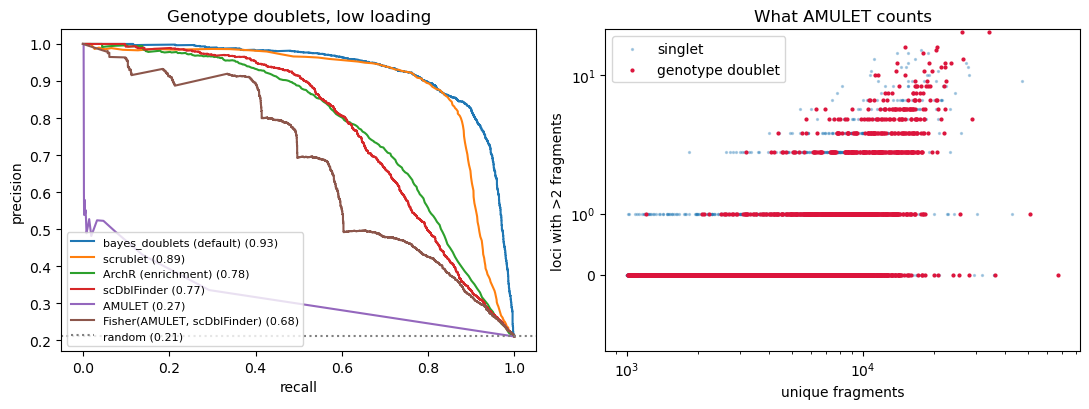

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for m, s in scores.items():
    p, r, _ = precision_recall_curve(y, s)
    ax[0].plot(r, p, label=f"{m} ({average_precision_score(y, s):.2f})")
ax[0].axhline(y.mean(), color="grey", ls=":", label=f"random ({y.mean():.2f})")
ax[0].set(xlabel="recall", ylabel="precision", title="Genotype doublets, low loading")
ax[0].legend(fontsize=8)
nf = ev["n_fragment"]
ax[1].scatter(nf[~y], ev["amulet_nAbove2"][~y], s=2, alpha=0.3, label="singlet")
ax[1].scatter(nf[y], ev["amulet_nAbove2"][y], s=4, color="crimson", label="genotype doublet")
ax[1].set(xscale="log", yscale="symlog", xlabel="unique fragments",
          ylabel="loci with >2 fragments", title="What AMULET counts")
ax[1].legend()
plt.tight_layout()

Note the right panel: doublets have more fragments *and* more loci covered by
more than two fragments. AMULET's power depends on depth. Its authors
recommend it for libraries with a median of 10–15k fragments per cell, and
this sample is shallower.

## Removing doublets

`filter_doublets` removes cells by one of four rules:

* `method="bayes"` (default) removes the cells that `bayes_doublets` calls
  doublets (posterior probability > 0.5). The posterior is calibrated to the
  Poisson-loading doublet rate of a standard 10x channel (here 11%). This chip
  was overloaded on purpose (21% genotype doublets), so pass the known rate,
  `epi.pp.doublets(adata, expected_doublet_rate=0.25)`, to remove more of them.
* `method="archr"` reproduces ArchR's `filterDoublets`. Within each sample it
  removes the top `n²/100000` cells by enrichment, the expected number of
  doublets for a 10x chip. It matches ArchR exactly on ArchR's own scores
  (gate F1 in the MANIFEST).
* `method="threshold"` removes cells with `score >= threshold`. For p- or
  q-value columns it removes cells with values `<= threshold`.
* `method="class"` removes cells labelled `"doublet"`, e.g. `scDblFinder_class`.

In [9]:
res = {}
for name, kw in {
    "bayes_doublets (default)": dict(),
    "ArchR rule": dict(method="archr"),
    "scDblFinder class": dict(method="class", score_key="scDblFinder_class"),
    "AMULET q < 0.01": dict(method="threshold", score_key="amulet_q", threshold=0.01),
    "Fisher p < 0.01": dict(method="threshold", score_key="doublet_combined_p", threshold=0.01),
}.items():
    a = adata.copy()
    epi.pp.filter_doublets(a, **kw, key_added="removed")
    rm = adata.obs_names.difference(a.obs_names)
    called = adata.obs.loc[rm, "demuxlet"]
    res[name] = dict(removed=len(rm), of_which_DBL=int((called == "DBL").sum()),
                     DBL_remaining=int((a.obs["demuxlet"] == "DBL").sum()))
pd.DataFrame(res).T

└─ [filter_doublets] removing 1,424 of 12,857 cells (11.1%)


└─ [filter_doublets] removing 1,653 of 12,857 cells (12.9%)


└─ [filter_doublets] removing 1,947 of 12,857 cells (15.1%)


└─ [filter_doublets] removing 245 of 12,857 cells (1.9%)


└─ [filter_doublets] removing 1,434 of 12,857 cells (11.2%)


,removed,of_which_DBL,DBL_remaining
bayes_doublets (default),1424,1391,1310
ArchR rule,1653,1429,1272
scDblFinder class,1947,1587,1114
AMULET q < 0.01,245,128,2573
Fisher p < 0.01,1434,1149,1552


In [10]:
epi.pp.filter_doublets(adata)                # default: bayes_doublet_class == "doublet"
adata

└─ [filter_doublets] removing 1,424 of 12,857 cells (11.1%)


AnnData object with n_obs × n_vars = 11433 × 6176550
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'demuxlet', 'cell_line', 'bayes_doublet_probability', 'bayes_doublet_score', 'bayes_doublet_class', 'bayes_doublet_pair', 'bayes_doublet_type', 'scrublet_score', 'scrublet_is_doublet', 'archr_doublet_score', 'archr_doublet_enrichment', 'scDblFinder_score', 'scDblFinder_class', 'amulet_nAbove2', 'amulet_p', 'amulet_q', 'amulet_class', 'doublet_combined_p', 'doublet_removed'
    uns: 'files', 'reference_sequences', 'bayes_doublet', 'archr_doublet', 'scDblFinder'

## What the benchmark shows

On these QC-filtered cells (≥ 1,000 fragments, no prior doublet removal), the default `bayes_doublets` ranks the genotype doublets best, followed by Scrublet; the ArchR score and scDblFinder come next. AMULET is weak here because the cells are shallow (median ≈ 4k fragments), below the 10–15k its authors recommend, and cell lines are aneuploid, so "more than two copies" is common in singlets too. Fisher-combining it with scDblFinder therefore lowers scDblFinder's AUPRC rather than raising it.

This dataset was used to *develop* `bayes_doublets`, so its numbers here are optimistic. On three held-out datasets with genotype or species truth (a 3-donor PBMC pool demultiplexed by genotype, and two 10x human–mouse mixtures) it had the best mean AUPRC of all detectors (0.78 vs 0.72 for SnapATAC2's scrublet, 0.70 for Epione's scrublet), with near-perfect scores on the species mixtures. On the PBMC pool, where cell states are continuous rather than discrete cell lines, SnapATAC2's scrublet ranked doublets better (AUPRC 0.42 vs 0.34), so check a second detector (`epi.pp.doublets(adata, method="scrublet")`) on primary tissue.

The pre-registered benchmark in `tests/parity/doublets/MANIFEST.md` also scores the authors' *published* cell sets of both loadings. Those sets turn out to be already doublet-filtered: they keep about 14% of the genotype doublets that pass QC but about 91% of the singlets. Every method looks poor on them, because the remaining doublets are the hard ones. Use QC-only cells like these when you compare methods.

On a single, shallow dataset of cell lines, no ranking should be over-generalised. Cell lines differ more than cell types do, which favours methods based on simulated doublets.